In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data loading
data_dir = Path("../data/raw")

train_values = pd.read_csv(data_dir / "Training set values.csv")
train_labels = pd.read_csv(data_dir / "Training set labels.csv")
test_values = pd.read_csv(data_dir / "Test set values.csv")

# Merge training data
df = train_values.merge(
    train_labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

print("Training dataset shape:", df.shape)
print("Test dataset shape:", test_values.shape)

Training dataset shape: (59400, 41)
Test dataset shape: (14850, 40)


# Categorical Analysis

In [3]:
target = "status_group"

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop(target).tolist()

numerical_cols = df.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical variables:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical variables:", len(numerical_cols))
print(numerical_cols)

Categorical variables: 30
['date_recorded', 'funder', 'installer', 'wpt_name', 'basin', 'subvillage', 'region', 'lga', 'ward', 'public_meeting', 'recorded_by', 'scheme_management', 'scheme_name', 'permit', 'extraction_type', 'extraction_type_group', 'extraction_type_class', 'management', 'management_group', 'payment', 'payment_type', 'water_quality', 'quality_group', 'quantity', 'quantity_group', 'source', 'source_type', 'source_class', 'waterpoint_type', 'waterpoint_type_group']

Numerical variables: 10
['id', 'amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'region_code', 'district_code', 'population', 'construction_year']


In [4]:
# Cardinality analysis

cardinality = pd.DataFrame({
    "Unique values": df[categorical_cols].nunique(),
    "Missing values": df[categorical_cols].isna().sum()
})

cardinality = cardinality.sort_values(
    by="Unique values",
    ascending=False
)

display(cardinality)

,Unique values,Missing values
wpt_name,37399,2
subvillage,19287,371
scheme_name,2695,28810
installer,2145,3655
ward,2092,0
funder,1896,3637
date_recorded,356,0
lga,125,0
region,21,0
extraction_type,18,0


In [5]:
# Top 10 categories for each categorical variable

for col in categorical_cols:
    print(f"\n{'=' * 50}")
    print(f"Variable: {col}")
    print(df[col].value_counts(dropna=False).head(10))


Variable: date_recorded
date_recorded
2011-03-15    572
2011-03-17    558
2013-02-03    546
2011-03-14    520
2011-03-16    513
2011-03-18    497
2011-03-19    466
2013-02-04    464
2013-01-29    459
2011-03-04    458
Name: count, dtype: int64

Variable: funder
funder
Government Of Tanzania    9084
NaN                       3637
Danida                    3114
Hesawa                    2202
Rwssp                     1374
World Bank                1349
Kkkt                      1287
World Vision              1246
Unicef                    1057
Tasaf                      877
Name: count, dtype: int64

Variable: installer
installer
DWE           17402
NaN            3655
Government     1825
RWE            1206
Commu          1060
DANIDA         1050
KKKT            898
Hesawa          840
0               777
TCRS            707
Name: count, dtype: int64

Variable: wpt_name
wpt_name
none               3563
Shuleni            1748
Zahanati            830
Msikitini           535
Kanisani    

# Tableau synthétique des catégories dominantes

In [6]:

frequency_summary = []

for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)

    frequency_summary.append({
        "Variable": col,
        "Top category": str(counts.index[0]),
        "Top category count": counts.iloc[0],
        "Top category (%)": round(counts.iloc[0] / len(df) * 100, 2),
        "Number of categories": df[col].nunique(),
        "Missing values": df[col].isna().sum()
    })

frequency_summary = pd.DataFrame(frequency_summary)

display(
    frequency_summary.sort_values(
        by="Top category (%)",
        ascending=False
    )
)

,Variable,Top category,Top category count,Top category (%),Number of categories,Missing values
10,recorded_by,GeoData Consultants Ltd,59400,100.00,1,0
18,management_group,user-group,52490,88.37,5,0
9,public_meeting,True,51011,85.88,2,3334
22,quality_group,good,50818,85.55,6,0
21,water_quality,soft,50818,85.55,8,0
27,source_class,groundwater,45794,77.09,3,0
17,management,vwc,40507,68.19,12,0
13,permit,True,38852,65.41,2,3056
11,scheme_management,VWC,36793,61.94,11,3878
29,waterpoint_type_group,communal standpipe,34625,58.29,6,0


In [7]:
# Analyse des variables catégorielles par rapport à la cible

selected_cols = [
    "quantity",
    "water_quality",
    "source",
    "extraction_type",
    "waterpoint_type",
    "payment",
    "management",
    "region"
]

for col in selected_cols:
    print(f"\n{'=' * 60}")
    print(f"Variable : {col}")

    distribution = pd.crosstab(
        df[col],
        df[target],
        normalize="index"
    ) * 100

    display(distribution.round(2))


Variable : quantity


status_group,functional,functional needs repair,non functional
quantity,,,
dry,2.51,0.59,96.89
enough,65.23,7.23,27.54
insufficient,52.32,9.58,38.09
seasonal,57.41,10.27,32.32
unknown,27.00,1.77,71.23



Variable : water_quality


status_group,functional,functional needs repair,non functional
water_quality,,,
coloured,50.20,11.02,38.78
fluoride,75.50,6.50,18.00
fluoride abandoned,35.29,0.00,64.71
milky,54.48,1.74,43.78
salty,45.72,4.63,49.65
salty abandoned,51.33,21.24,27.43
soft,56.59,7.68,35.72
unknown,14.07,1.87,84.06



Variable : source


status_group,functional,functional needs repair,non functional
source,,,
dam,38.57,3.66,57.77
hand dtw,56.86,1.95,41.19
lake,21.18,1.57,77.25
machine dbh,48.96,4.43,46.61
other,59.43,0.47,40.09
rainwater harvesting,60.39,13.68,25.93
river,56.86,12.70,30.44
shallow well,49.48,5.69,44.83
spring,62.23,7.50,30.27


... (6 outputs left out)


Variable : management


status_group,functional,functional needs repair,non functional
management,,,
company,38.98,2.19,58.83
other,59.83,6.52,33.65
other - school,23.23,1.01,75.76
parastatal,57.69,11.93,30.37
private operator,74.89,2.23,22.88
trust,58.97,7.69,33.33
unknown,39.93,4.81,55.26
vwc,50.42,6.89,42.69
water authority,49.34,5.75,44.91



Variable : region


status_group,functional,functional needs repair,non functional
region,,,
Arusha,68.48,5.22,26.30
Dar es Salaam,57.27,0.37,42.36
Dodoma,45.84,9.50,44.66
Iringa,78.22,2.32,19.46
Kagera,52.08,9.17,38.75
Kigoma,48.40,21.41,30.18
Kilimanjaro,60.29,7.35,32.36
Lindi,29.75,6.02,64.23
Manyara,62.35,6.06,31.59


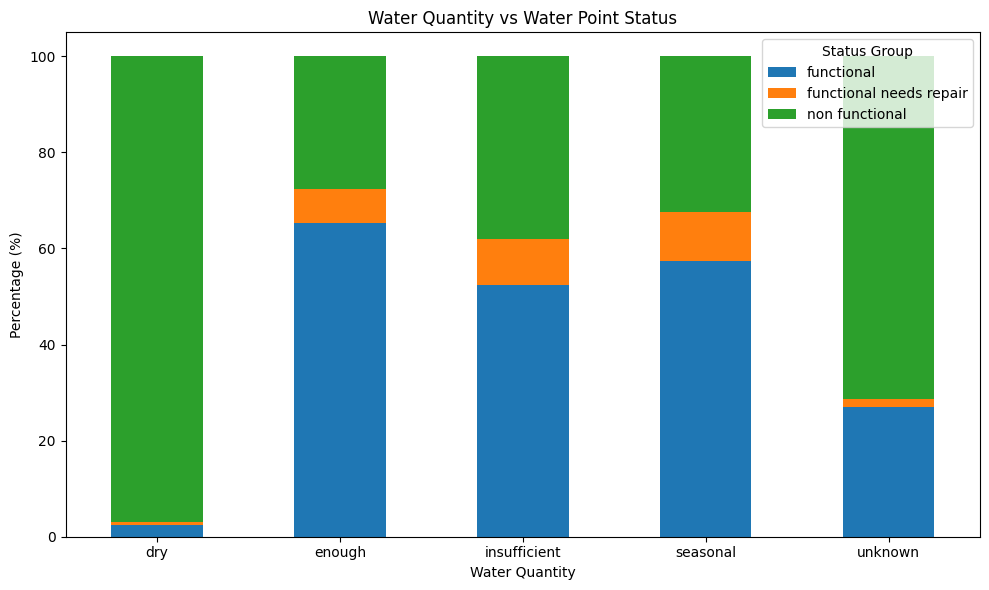

In [8]:
# Visualisation de quantity par rapport à status_group

quantity_distribution = pd.crosstab(
    df["quantity"],
    df[target],
    normalize="index"
) * 100

quantity_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Water Quantity vs Water Point Status")
plt.xlabel("Water Quantity")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Status Group")
plt.tight_layout()
plt.show()

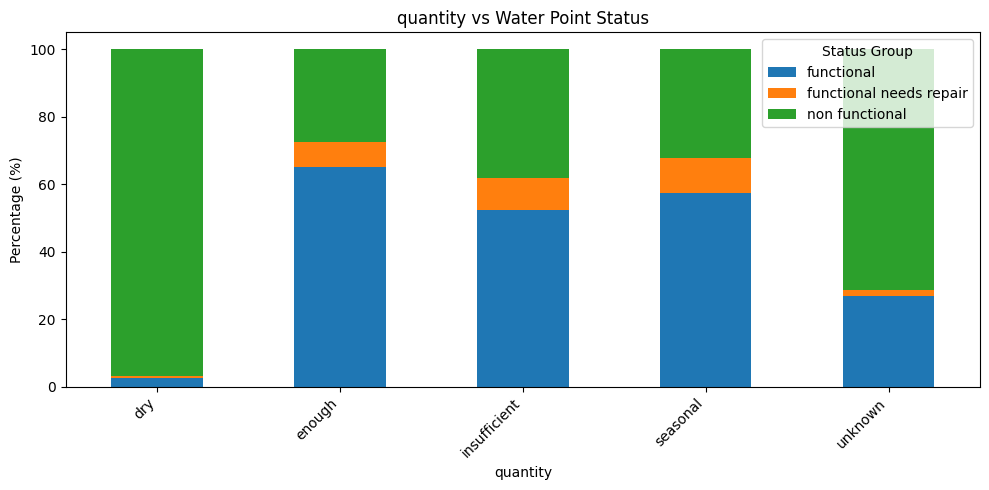

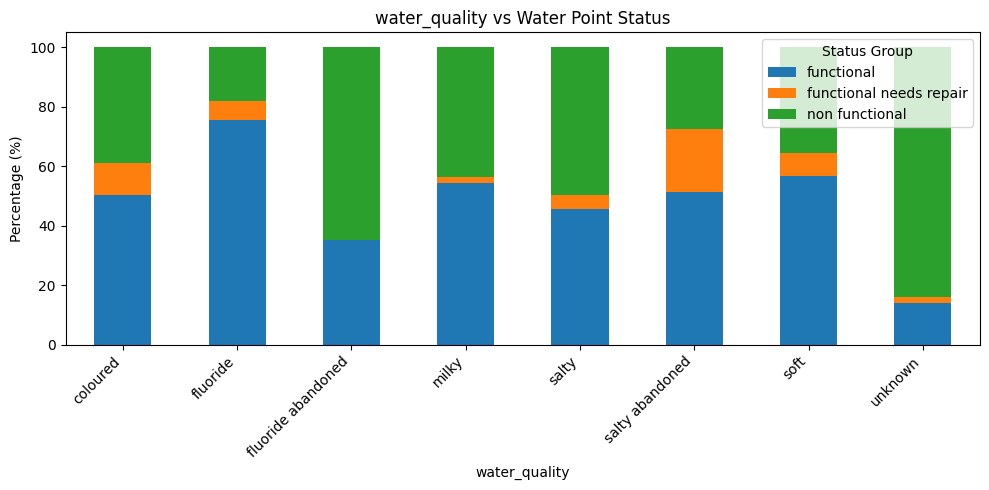

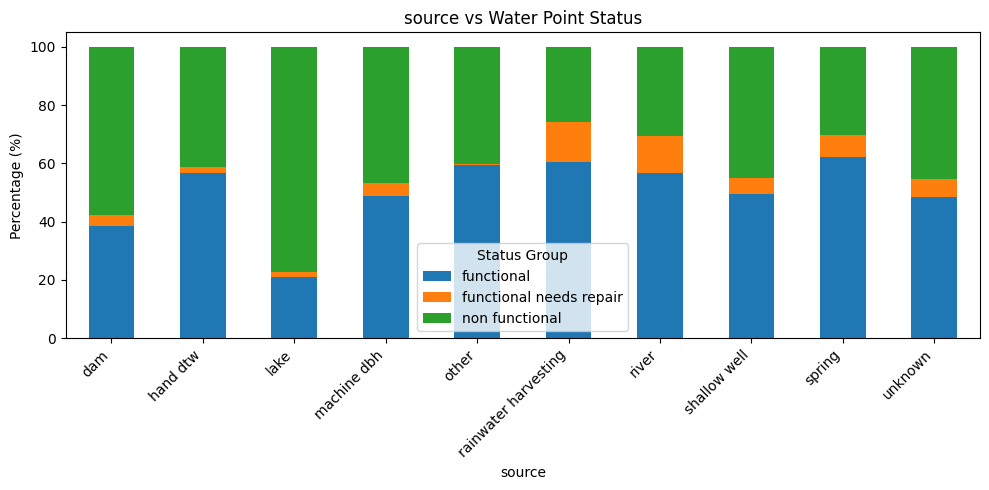

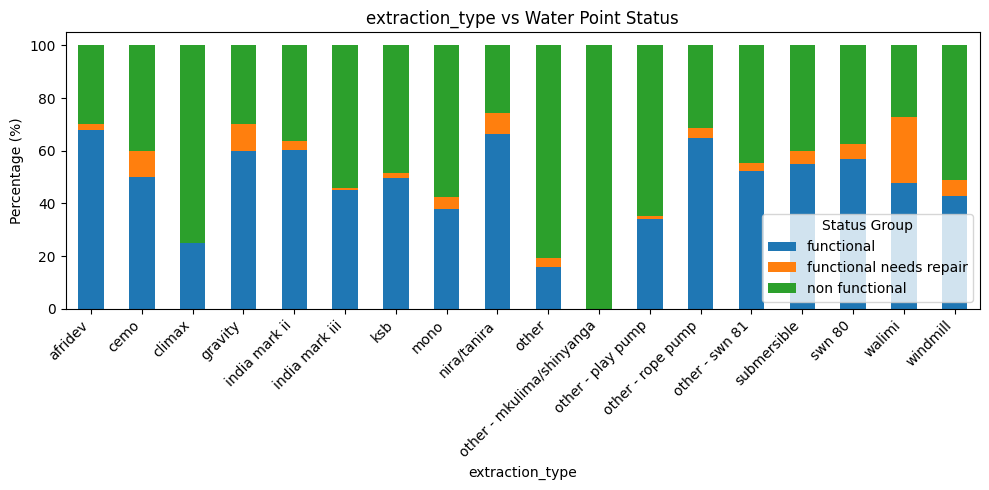

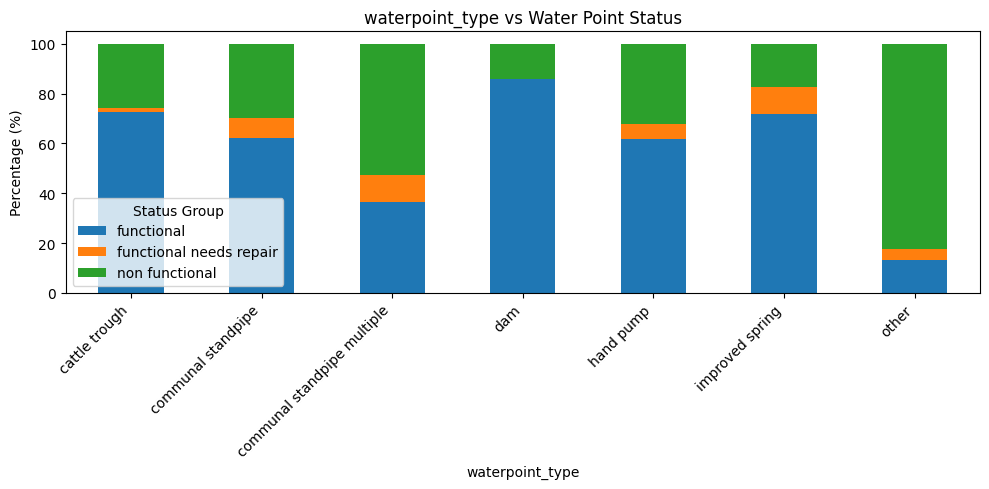

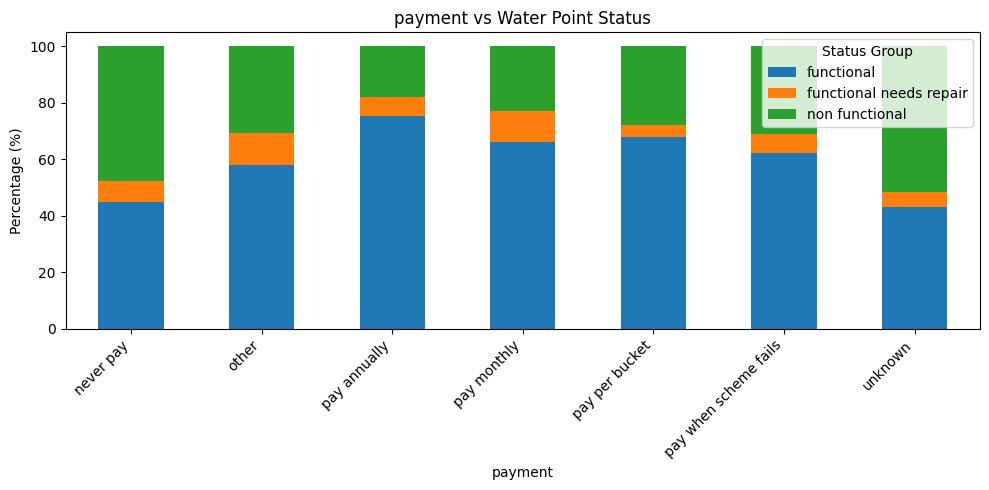

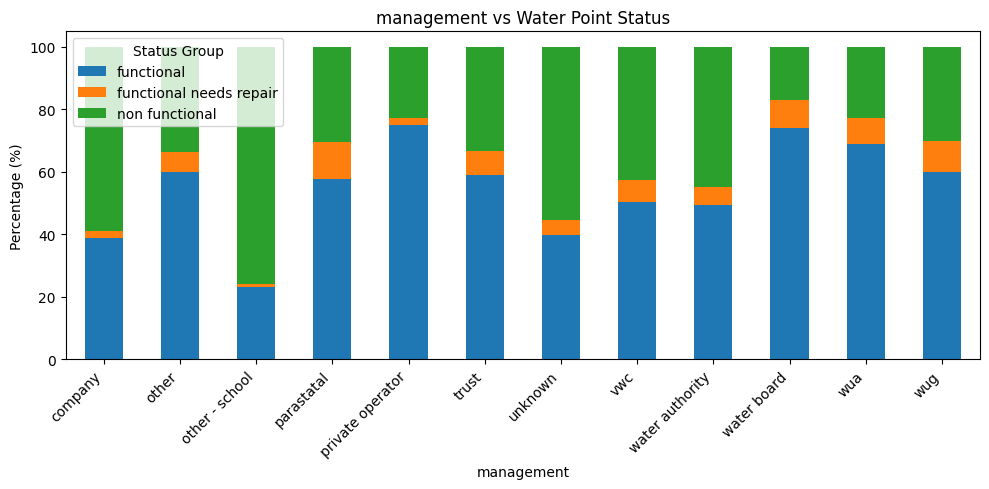

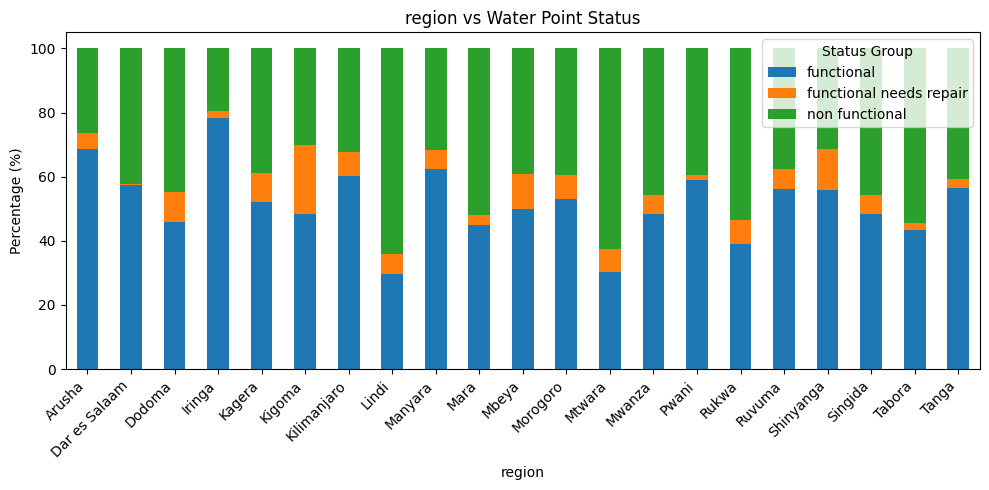

In [9]:
# Visualisation des variables catégorielles sélectionnées

for col in selected_cols:
    distribution = pd.crosstab(
        df[col],
        df[target],
        normalize="index"
    ) * 100

    distribution.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )

    plt.title(f"{col} vs Water Point Status")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Status Group")
    plt.tight_layout()
    plt.show()

In [10]:
numerical_analysis_cols = [
    "amount_tsh",
    "gps_height",
    "longitude",
    "latitude",
    "num_private",
    "population",
    "construction_year"
]
# Statistical summary of numerical variables

display(
    df[numerical_analysis_cols].describe().T.round(2)
)

,count,mean,std,min,25%,50%,75%,max
amount_tsh,59400.0,317.65,2997.57,0.00,0.00,0.00,20.00,350000.00
gps_height,59400.0,668.30,693.12,-90.00,0.00,369.00,1319.25,2770.00
longitude,59400.0,34.08,6.57,0.00,33.09,34.91,37.18,40.35
latitude,59400.0,-5.71,2.95,-11.65,-8.54,-5.02,-3.33,-0.00
num_private,59400.0,0.47,12.24,0.00,0.00,0.00,0.00,1776.00
population,59400.0,179.91,471.48,0.00,0.00,25.00,215.00,30500.00
construction_year,59400.0,1300.65,951.62,0.00,0.00,1986.00,2004.00,2013.00


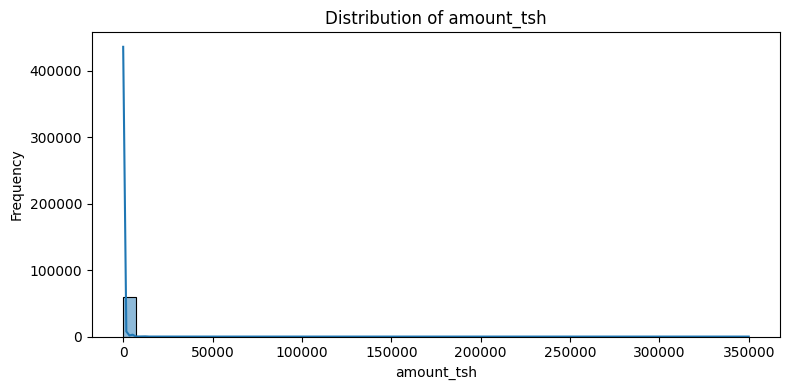

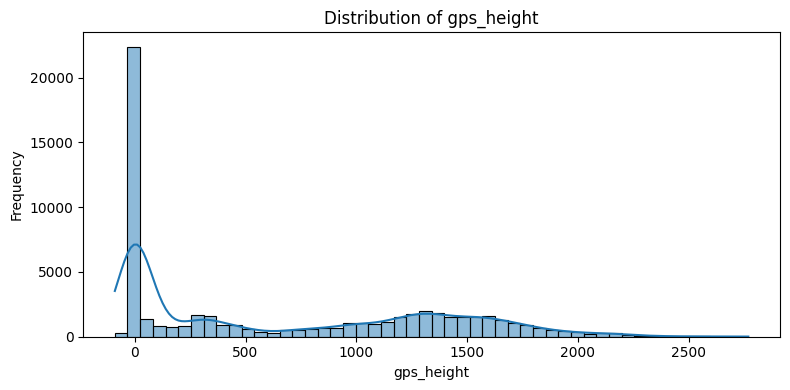

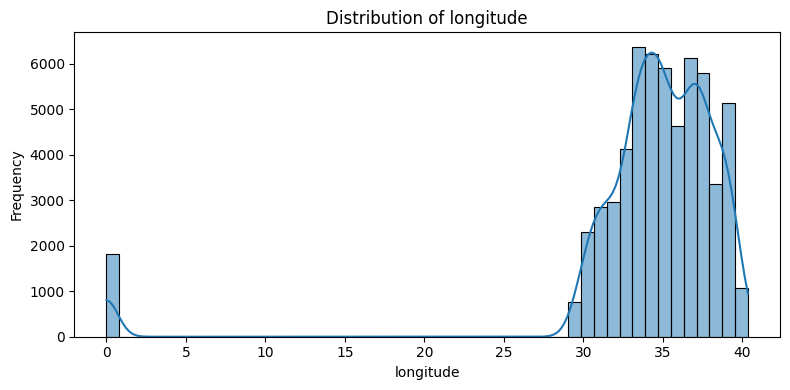

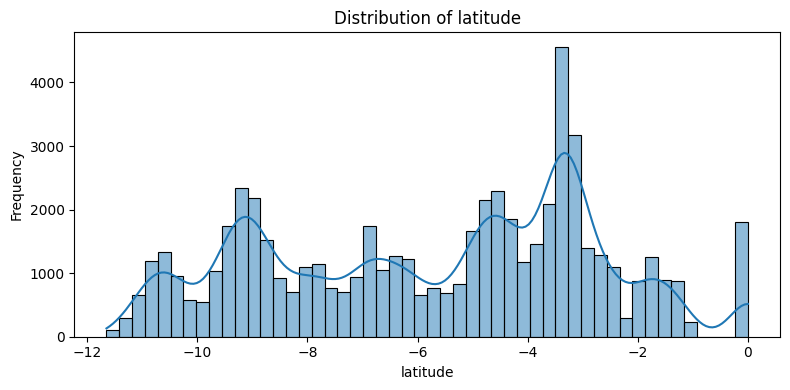

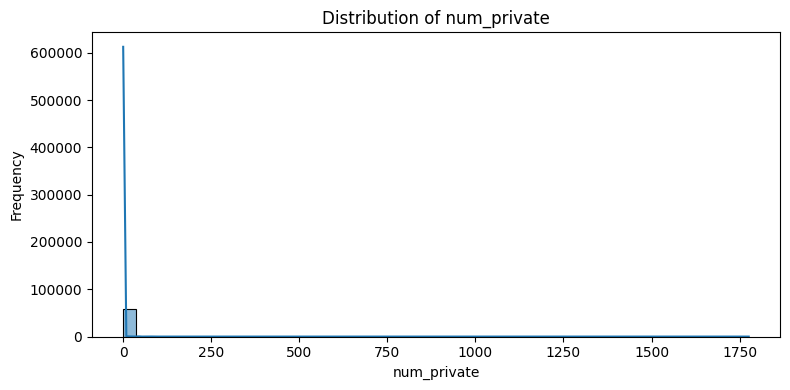

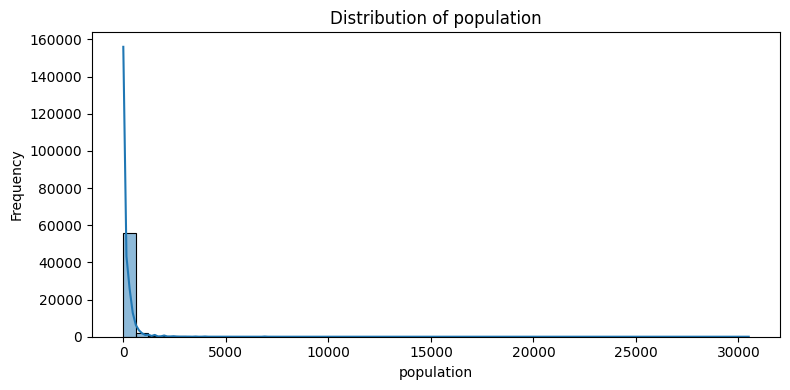

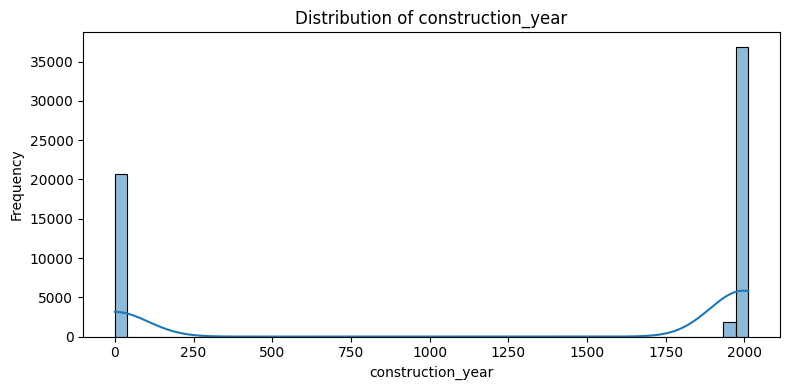

In [11]:
# Distribution des variables numériques

for col in numerical_analysis_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=50,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

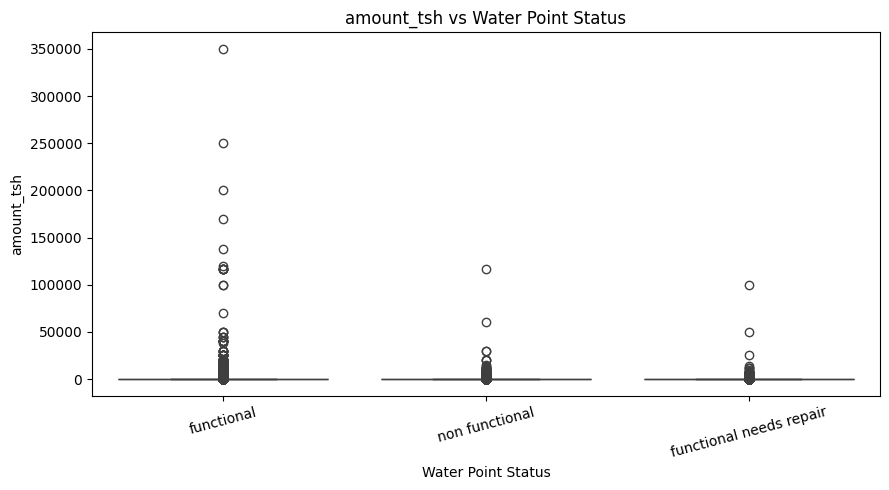

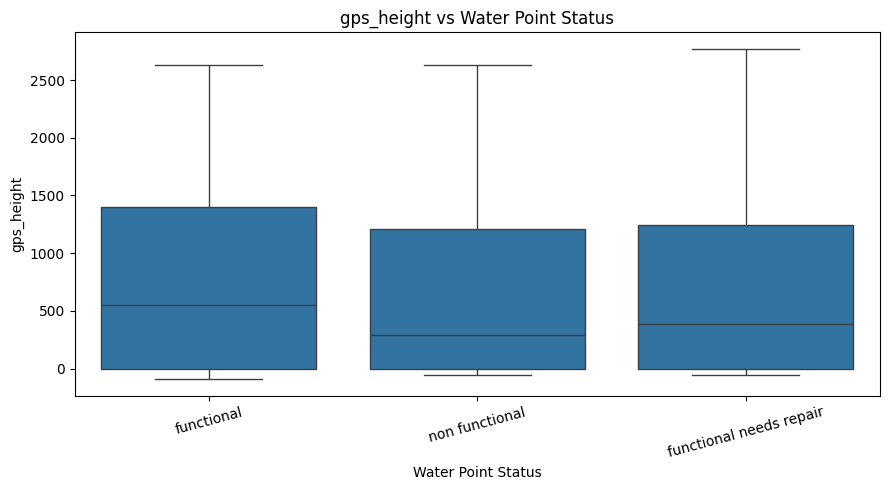

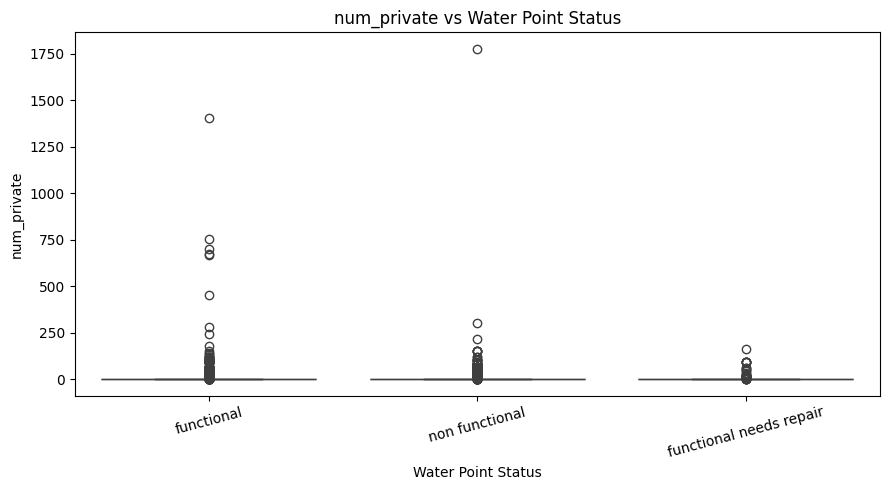

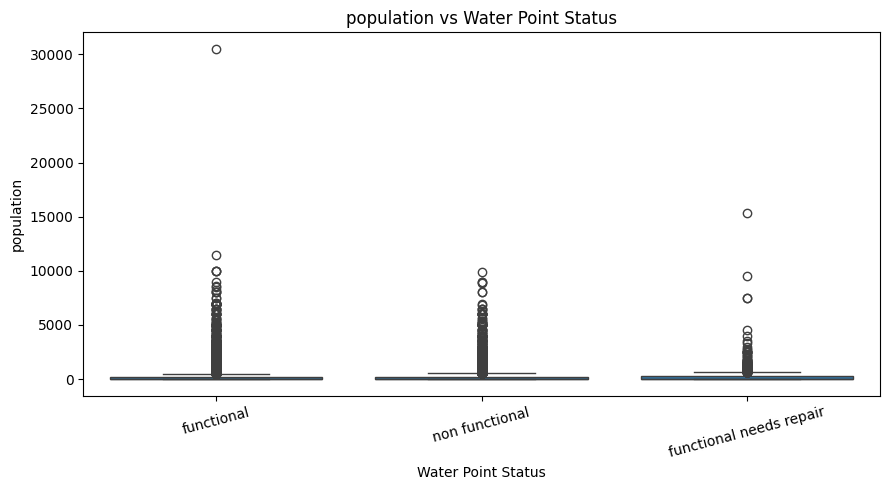

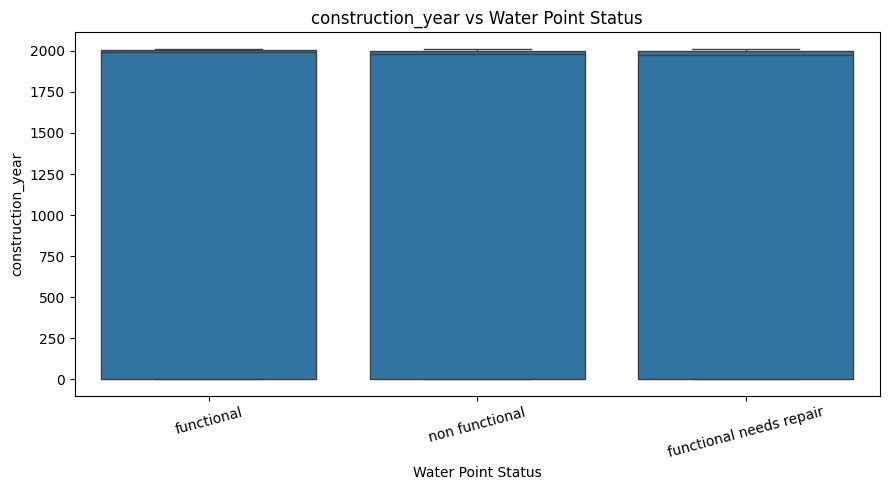

In [12]:
# Analyse des variables numériques selon le statut du point d'eau

numerical_features = [
    "amount_tsh",
    "gps_height",
    "num_private",
    "population",
    "construction_year"
]

for col in numerical_features:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=target,
        y=col
    )

    plt.title(f"{col} vs Water Point Status")
    plt.xlabel("Water Point Status")
    plt.ylabel(col)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [13]:
status_means = df.groupby(target)[numerical_features].mean().T

display(status_means.round(2))

status_group,functional,functional needs repair,non functional
amount_tsh,461.80,267.07,123.48
gps_height,740.13,627.61,574.46
num_private,0.54,0.31,0.41
population,187.55,175.10,170.02
construction_year,1345.57,1168.41,1262.18


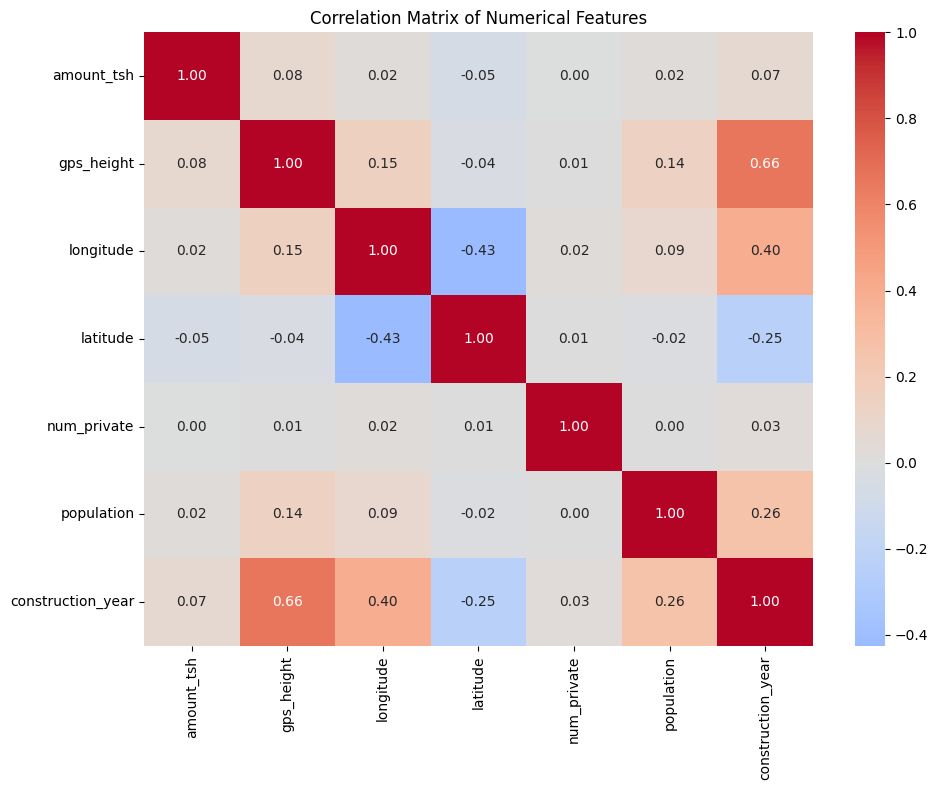

In [14]:
correlation_matrix = df[numerical_analysis_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

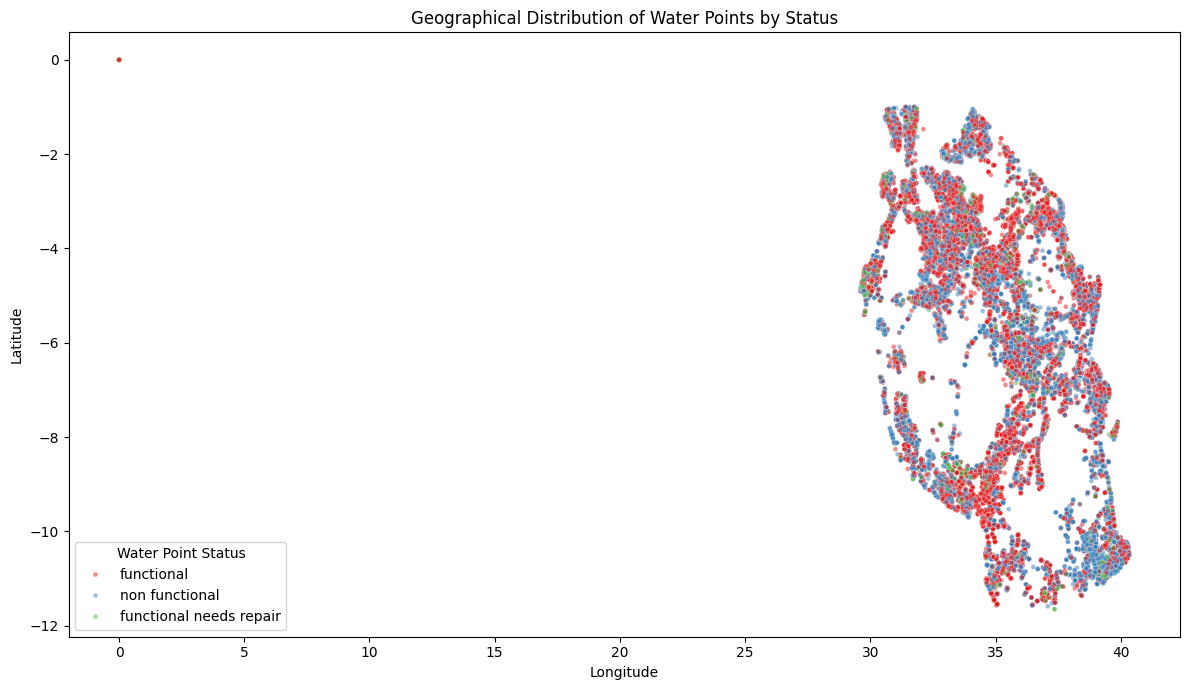

In [15]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue=target,
    alpha=0.5,
    s=12,
    palette="Set1"
)

plt.title("Geographical Distribution of Water Points by Status")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Water Point Status")
plt.tight_layout()
plt.show()

In [16]:
region_status = pd.crosstab(
    df["region"],
    df[target],
    normalize="index"
) * 100

region_status = region_status.sort_values(
    "non functional",
    ascending=False
)

display(region_status.round(2))

status_group,functional,functional needs repair,non functional
region,,,
Lindi,29.75,6.02,64.23
Mtwara,30.29,7.28,62.43
Tabora,43.29,2.30,54.42
Rukwa,39.10,7.47,53.43
Mara,45.00,3.05,51.96
Mwanza,48.42,5.90,45.68
Singida,48.30,6.12,45.58
Dodoma,45.84,9.50,44.66
Dar es Salaam,57.27,0.37,42.36


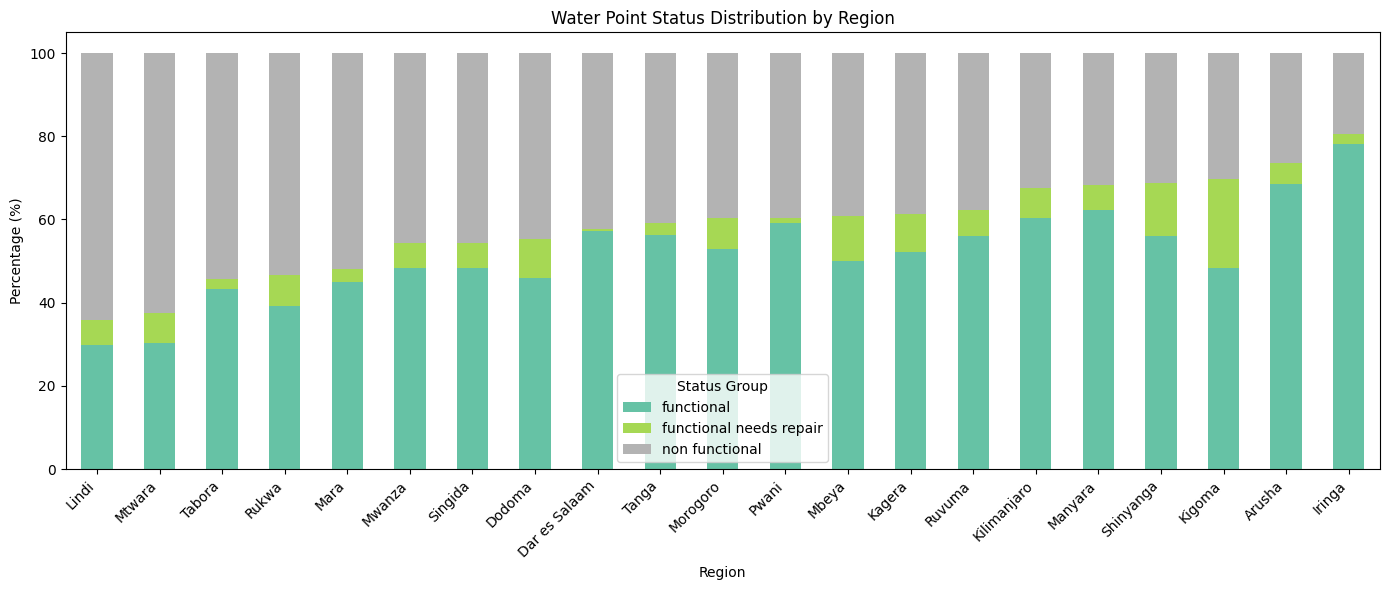

In [17]:
region_status.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    colormap="Set2"
)

plt.title("Water Point Status Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Status Group")
plt.tight_layout()
plt.show()

In [18]:
# Conversion en datetime
df["date_recorded"] = pd.to_datetime(df["date_recorded"])

# Extraction de l'année
df["recorded_year"] = df["date_recorded"].dt.year

# Examiner la période couverte
print("Date minimale :", df["date_recorded"].min())
print("Date maximale :", df["date_recorded"].max())

# Nombre d'enregistrements par année
display(df["recorded_year"].value_counts().sort_index())

Date minimale : 2002-10-14 00:00:00
Date maximale : 2013-12-03 00:00:00


recorded_year
2002        1
2004       30
2011    28674
2012     6424
2013    24271
Name: count, dtype: int64

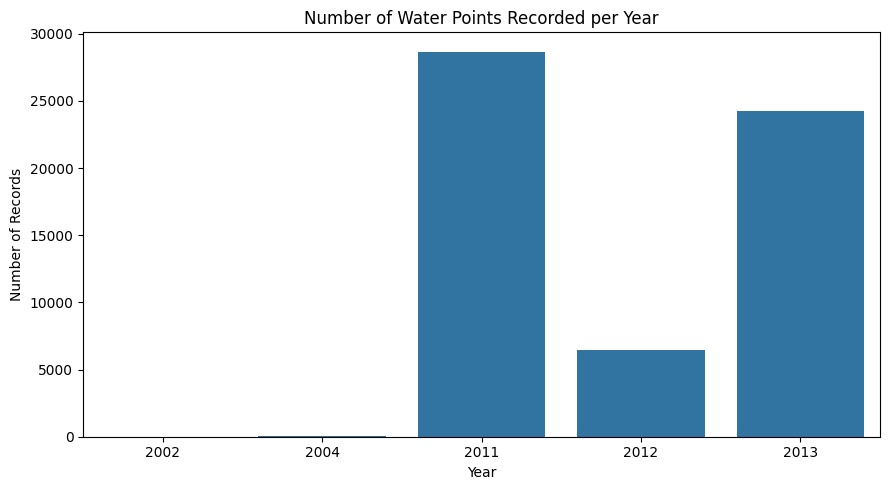

In [19]:
year_counts = df["recorded_year"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values
)

plt.title("Number of Water Points Recorded per Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [20]:
year_status = pd.crosstab(
    df["recorded_year"],
    df[target],
    normalize="index"
) * 100

display(year_status.round(2))

status_group,functional,functional needs repair,non functional
recorded_year,,,
2002,100.00,0.00,0.00
2004,33.33,3.33,63.33
2011,56.57,6.32,37.11
2012,48.66,5.64,45.70
2013,53.16,8.83,38.02
